# The AI-Native Threat Landscape: How AI Changes Attack and Defence

> **Who is this for:** anyone who builds or runs AI systems (or plans to work in security) and wants a clear, honest picture of how AI is changing cyber attacks and cyber defence. You do not need any security background.
>
> **What you will learn:**
> - the security basics in simple words: the **CIA triad**, threat, vulnerability, exploit, risk, **attack surface**, the **kill chain** and **MITRE ATT&CK**, **defence in depth** and **zero trust**
> - how AI changes **offence**: reconnaissance, personalised phishing, voice and video **deepfake fraud**, AI-assisted vulnerability discovery, **agentic attack tools**, AI-assisted malware, attacks **on** AI systems, shadow-AI data leaks and the **slopsquatting** supply-chain risk
> - for each one, **what verified reports show versus what is hype**
> - how AI changes **defence** (an overview; the hands-on part is notebook 03)
> - the **attacker-defender asymmetry** debate
> - **threat modelling** a small AI app with **STRIDE** plus an AI-specific extension, done in Python
> - **risk scoring** (likelihood x impact) and a risk matrix
> - a timeline of **verified** AI-security events from 2024 to 2026, and the policy landscape
>
> **Prerequisites:** basic Python and pandas. Helpful: [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb) (STRIDE, OWASP, secrets), [LLM security](../08_LLM/16_llm_security.ipynb), [agent security](../10_Agents/08_agent_security.ipynb).
>
> **Time needed:** about 2-3 hours to read and play. The code runs in a few seconds.
>
> **Runs on:** CPU, no API key, no internet. All systems, people and incidents in the code are made up, except the clearly labelled real-world timeline in section 9.

### A note on ethics and the law (read this first)

This notebook explains how attacks work **at a conceptual level** so that you can defend against them. It contains **no working attack code**. Every demo targets a toy system that lives inside this notebook.

- Only test systems you **own** or have **written permission** to test. Unauthorised access is a crime in most countries (for example the Computer Misuse Act in the UK and the Computer Fraud and Abuse Act in the US). The details differ by country, so check your local law.
- If you find a weakness in someone else's system, use **responsible disclosure**: report it privately to the owner, give them time to fix it, and do not use or publish it before then.
- The track guide [README](README.md) has the full ethics and legal box.

## 0. Setup

We only need the standard library, numpy, pandas and matplotlib. We fix a random seed so that every run prints the same numbers.

In [1]:
import random, math, re, hashlib, difflib, textwrap   # standard-library helpers
from itertools import product

import numpy as np                    # numbers and arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # plots

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 80)   # show long text in tables
pd.set_option("display.width", 160)
print("ready, seed =", SEED)

ready, seed = 42


## 1. Security basics in simple words

Before we talk about AI, we need a small shared vocabulary. Every term below is used in the rest of the track.

### 1.1 The CIA triad

**What it is.** The three things security tries to protect:

| Letter | Property | Simple meaning | Broken when... |
|---|---|---|---|
| C | **Confidentiality** | only the right people can **read** it | customer data leaks, a chatbot reveals another user's chat |
| I | **Integrity** | nobody can **change** it without permission | a payment amount is altered, training data is poisoned |
| A | **Availability** | it **works** when you need it | ransomware locks the files, a bot floods your LLM API with requests |

**Simple analogy.** A bank locker. Confidentiality: only you can open it. Integrity: nobody swaps your gold for fake gold. Availability: the bank is open when you need your things.

**When to use it.** Every time you look at an incident or a design, ask "which of C, I or A could break here?". It is a quick checklist, not a full method.

In [2]:
# Toy incidents (made up). For each one we record which CIA properties were broken.
incidents = [
    ("Support chatbot shows one customer's order history to another customer", "C"),
    ("Attacker edits product prices in the database",                          "I"),
    ("Ransomware encrypts the file server",                                    "A,I"),
    ("Bot sends 10 million prompts and the LLM bill explodes; service slows",   "A"),
    ("Poisoned documents added to the RAG knowledge base",                     "I"),
    ("Employee pastes secret source code into a public AI chatbot",           "C"),
]
df_cia = pd.DataFrame(incidents, columns=["incident", "broken"])
for letter, name in [("C", "Confidentiality"), ("I", "Integrity"), ("A", "Availability")]:
    df_cia[name] = df_cia["broken"].str.contains(letter).map({True: "X", False: ""})
print(df_cia.drop(columns="broken").to_string(index=False))

                                                              incident Confidentiality Integrity Availability
Support chatbot shows one customer's order history to another customer               X                       
                         Attacker edits product prices in the database                         X             
                                   Ransomware encrypts the file server                         X            X
 Bot sends 10 million prompts and the LLM bill explodes; service slows                                      X
                    Poisoned documents added to the RAG knowledge base                         X             
           Employee pastes secret source code into a public AI chatbot               X                       


### 1.2 Threat, vulnerability, exploit, risk

| Term | Simple meaning | House analogy |
|---|---|---|
| **Asset** | something of value you want to protect | your house and what is inside |
| **Threat** | someone or something that could cause harm | a burglar |
| **Vulnerability** | a weakness that could be used | a broken window latch |
| **Exploit** | a method or piece of code that uses a vulnerability | the trick for opening that latch |
| **Attack** | an actual attempt to cause harm | the burglar trying the window tonight |
| **Risk** | how likely harm is, times how bad it would be | "broken latch + area with many burglaries + jewellery inside = high risk" |
| **Control / mitigation** | something that reduces risk | fixing the latch, an alarm, a safe |
| **Zero-day** | a vulnerability the defender does not know about yet, so there is no fix | a latch flaw even the manufacturer does not know about |
| **CVE** | a public ID for a known vulnerability, e.g. `CVE-2025-6965` | the recall number for a faulty latch model |

A short formula you will see everywhere: **risk = likelihood x impact**. We compute it in section 8.

### 1.3 Attack surface

**What it is.** The **attack surface** is the sum of all the places where an attacker can try to get in or cause harm: every login page, API, open network port, file upload, third-party library, employee inbox and, for AI apps, every prompt, document, tool and plugin.

**Simple analogy.** Every door and window of a house. A house with 30 windows is harder to protect than one with 3.

**How AI changes it.** An AI app adds new "windows": the prompt box, documents the model reads (RAG), tools the agent can call, plugins and agent "skills", model files downloaded from the internet, and the memory the agent keeps between sessions. The rule of thumb: **reduce the surface** (fewer tools, fewer permissions, fewer exposed endpoints) before you add more locks.

## 2. How attacks unfold: the kill chain and MITRE ATT&CK

### 2.1 The Cyber Kill Chain

**What it is.** A model, published by Lockheed Martin in 2011, that splits an intrusion into seven ordered steps. The idea is borrowed from the military: if you break **any** link of the chain, the attack fails.

**Simple analogy.** A bank robbery film: scout the bank, prepare tools, get inside, open the vault, stay hidden, call the getaway car, leave with the money. Stop any step and the robbery fails.

```mermaid
flowchart LR
    R[1 Reconnaissance<br/>learn about target] --> W[2 Weaponisation<br/>prepare the attack]
    W --> D[3 Delivery<br/>email, website, USB]
    D --> E[4 Exploitation<br/>weakness is used]
    E --> I[5 Installation<br/>attacker stays]
    I --> C[6 Command and control<br/>remote channel]
    C --> A[7 Actions on objectives<br/>steal, encrypt, destroy]
```

**When to use it.** Good for explaining an attack story and for asking "at which step could we have stopped this?". It is a bit old-fashioned: it fits malware delivered by email very well, but fits insider threats and cloud misuse less well.

### 2.2 MITRE ATT&CK

**What it is.** [MITRE ATT&CK](https://attack.mitre.org) is a free, public knowledge base of real attacker behaviour. **Tactics** are the attacker's goals ("why"), and **techniques** are the ways to reach them ("how"). The Enterprise matrix has 14 tactics. Security teams use it to describe incidents in a shared language and to check which behaviours their detections cover.

**MITRE ATLAS** ([atlas.mitre.org](https://atlas.mitre.org)) is the sister knowledge base for attacks **on AI systems** (for example prompt injection, model theft, poisoned agent tools). Notebook 04 uses it.

The code below maps a **made-up** incident story onto ATT&CK tactics. This is what analysts do when they write an incident report.

In [3]:
# The 14 MITRE ATT&CK Enterprise tactics, in their usual order.
ATTACK_TACTICS = ["Reconnaissance", "Resource Development", "Initial Access", "Execution",
                  "Persistence", "Privilege Escalation", "Defense Evasion", "Credential Access",
                  "Discovery", "Lateral Movement", "Collection", "Command and Control",
                  "Exfiltration", "Impact"]

# A made-up incident at a made-up company, written as a timeline of observations.
timeline = [
    ("Day 1", "Attacker gathers staff names and roles from public profiles",   "Reconnaissance"),
    ("Day 2", "Registers a look-alike domain for the company",                 "Resource Development"),
    ("Day 3", "Sends a personalised email with a fake invoice link",           "Initial Access"),
    ("Day 3", "Victim enters password on a fake login page",                   "Credential Access"),
    ("Day 4", "Attacker logs in from a new country and lists shared folders",  "Discovery"),
    ("Day 4", "Adds a mail-forwarding rule so copies of mail go out",          "Persistence"),
    ("Day 5", "Downloads finance spreadsheets",                                "Collection"),
    ("Day 5", "Sends the files to an outside cloud account",                   "Exfiltration"),
]
df_tl = pd.DataFrame(timeline, columns=["when", "observation", "tactic"])
df_tl["tactic_no"] = df_tl["tactic"].map(lambda t: ATTACK_TACTICS.index(t) + 1)
print(df_tl.to_string(index=False))

seen = set(df_tl["tactic"])
print("\nTactics NOT seen in this incident:", [t for t in ATTACK_TACTICS if t not in seen])

 when                                                  observation               tactic  tactic_no
Day 1  Attacker gathers staff names and roles from public profiles       Reconnaissance          1
Day 2                Registers a look-alike domain for the company Resource Development          2
Day 3          Sends a personalised email with a fake invoice link       Initial Access          3
Day 3                  Victim enters password on a fake login page    Credential Access          8
Day 4 Attacker logs in from a new country and lists shared folders            Discovery          9
Day 4         Adds a mail-forwarding rule so copies of mail go out          Persistence          5
Day 5                               Downloads finance spreadsheets           Collection         11
Day 5                  Sends the files to an outside cloud account         Exfiltration         13

Tactics NOT seen in this incident: ['Execution', 'Privilege Escalation', 'Defense Evasion', 'Lateral Movemen

**What just happened?** We tagged every step of the story with an ATT&CK tactic. Two things follow from this:
1. You can ask, for each tactic, **"do we have a detection for this?"**. That is called **coverage mapping**.
2. Notice that most steps are **ordinary actions** (a login, a mail rule, a download). Attackers often "live off the land", so good detection looks for **unusual behaviour**, not only for known malware. Notebook 03 builds such detectors.

## 3. Two design ideas: defence in depth and zero trust

### 3.1 Defence in depth

**What it is.** Use **several independent layers** of protection, so that one failure does not lead to a breach.

**Simple analogy.** A castle: a moat, then a wall, then guards, then a locked keep. An attacker must beat all of them.

**How it works.** If each layer misses an attack with some probability, and the layers fail **independently**, the chance that an attack gets through all of them is the **product** of the miss rates. The numbers below are illustrative, not measured.

In [4]:
# Illustrative miss rates (the share of attacks each layer fails to stop). Not real measurements.
layers = {
    "email filter":              0.10,
    "user training / reporting": 0.50,
    "phishing-resistant MFA":    0.05,
    "anomaly detection on logins": 0.30,
}
p_through = 1.0
print(f"{'after layer':30s} chance an attack is still going")
for name, miss in layers.items():
    p_through *= miss
    print(f"{name:30s} {p_through:8.4%}")

print("\nAny single layer alone lets through at least", f"{min(layers.values()):.0%}", "of attacks.")
print("Together (if independent):", f"{p_through:.4%}")

after layer                    chance an attack is still going
email filter                   10.0000%
user training / reporting       5.0000%
phishing-resistant MFA          0.2500%
anomaly detection on logins     0.0750%

Any single layer alone lets through at least 5% of attacks.
Together (if independent): 0.0750%


**The catch.** The product rule only holds if the layers fail **independently**. If one trick (say, an AI-written email with perfect grammar) beats both the email filter and the human, the layers are **correlated** and the real protection is weaker. That is why good layers use **different signals**: text, links, login behaviour, device, money flow. We see this again in notebook 03, where rewording beats a text classifier but URL and login checks still work.

### 3.2 Zero trust

**What it is.** "Never trust, always verify." No user, device or program is trusted just because it is **inside** the network. Every request is checked: who is asking, from which device, for what, and is that normal? (NIST SP 800-207 is the reference.)

**Simple analogy.** An office where your badge is checked at **every** door, not only at the front entrance. And your badge only opens the rooms you need for today's job.

**How it works.**
1. Verify identity strongly (MFA, ideally phishing-resistant passkeys).
2. Check the device and the context (location, time, risk signals).
3. Grant the **least privilege** needed, for a short time.
4. Log everything and keep checking.

**Why it matters for AI.** An AI agent is a new kind of "user". Zero trust says: give the agent its **own identity**, the smallest set of tools and permissions, short-lived credentials, and log every action. The OWASP agentic list calls the opposite "identity and privilege abuse".

Here is a tiny zero-trust **policy decision** function. It is a toy, but real policy engines work on the same idea.

In [5]:
def zero_trust_decision(req):
    # Return (decision, reasons) for one access request. All rules are toy examples.
    reasons = []
    if not req["mfa_passed"]:
        reasons.append("no MFA")
    if not req["device_managed"]:
        reasons.append("unmanaged device")
    if req["resource"] not in req["allowed_resources"]:
        reasons.append("resource not in role")          # least privilege
    if req["risk_score"] >= 70:
        reasons.append("high risk signals")
    if not reasons:
        return "ALLOW (short-lived token)", reasons
    if reasons == ["unmanaged device"]:
        return "ALLOW read-only", reasons                # step down instead of all-or-nothing
    return "DENY", reasons

requests = [
    dict(who="alice (human)", resource="payroll_db", allowed_resources={"payroll_db"}, mfa_passed=True,  device_managed=True,  risk_score=10),
    dict(who="bob (human)",   resource="payroll_db", allowed_resources={"wiki"},       mfa_passed=True,  device_managed=True,  risk_score=10),
    dict(who="carol (human)", resource="wiki",       allowed_resources={"wiki"},       mfa_passed=True,  device_managed=False, risk_score=20),
    dict(who="support-agent (AI)", resource="refund_api", allowed_resources={"ticket_db"}, mfa_passed=True, device_managed=True, risk_score=5),
    dict(who="alice (human)", resource="payroll_db", allowed_resources={"payroll_db"}, mfa_passed=True,  device_managed=True,  risk_score=85),
]
for r in requests:
    decision, why = zero_trust_decision(r)
    print(f"{r['who']:20s} -> {r['resource']:11s} : {decision:26s} {why}")

alice (human)        -> payroll_db  : ALLOW (short-lived token)  []
bob (human)          -> payroll_db  : DENY                       ['resource not in role']
carol (human)        -> wiki        : ALLOW read-only            ['unmanaged device']
support-agent (AI)   -> refund_api  : DENY                       ['resource not in role']
alice (human)        -> payroll_db  : DENY                       ['high risk signals']


## 4. How AI changes offence

This is the core of the notebook. For each area we give: **what it is**, **how AI changes it**, **what verified reports show** (and what is still hype), and **the main defence**.

A word on evidence. Most public facts come from **threat-intelligence reports** written by AI labs and security vendors (Google Threat Intelligence Group, Microsoft, OpenAI, Anthropic, CrowdStrike) and from **government agencies** (the UK NCSC, the US CISA, FBI and FinCEN). These are useful but each has limits: a vendor sees only its own customers or its own model, and some numbers cannot be checked from outside. In this notebook:
- **Verified** means the event is described in a primary source (the organisation's own report, an official advisory, a CVE, or a peer-reviewed paper).
- **Claimed** means a vendor or lab says it, but outsiders cannot fully check it yet.

The big picture, as of late 2026, from several independent sources:

> **Most AI misuse speeds up old attack playbooks rather than creating brand-new kinds of attack.** OpenAI's October 2025 report says threat actors "bolt AI onto old playbooks to move faster". The UK NCSC's assessment (May 2025) judges that AI will "highly likely" increase the volume and impact of intrusions through existing techniques "rather than creating novel threat vectors" up to 2027. At the same time, 2025-2026 brought several real **firsts**, covered below.

```mermaid
flowchart TB
    AI[Generative AI and agents] --> S[Scale: more attacks per attacker]
    AI --> Q[Quality: fluent, personalised lures]
    AI --> SP[Speed: faster recon, scripting, exploit work]
    AI --> L[Lower skill barrier: less expert actors can do more]
    AI --> N[New targets: the AI apps and agents themselves]
```

### 4.1 AI-assisted reconnaissance

**What it is.** **Reconnaissance** ("recon") is the first step of most attacks: learning about the target. Who works there, which software they use, which email format, which partners.

**How AI changes it.** An LLM can read and summarise large amounts of public information (company pages, job ads that list software, social profiles, code repositories) and turn it into a target profile in minutes. Google's threat reports (January and November 2025) describe state-backed groups using Gemini to research target organisations, infrastructure and vulnerabilities.

**Verified vs hype.** Verified: recon and research are among the **most common** misuse types in every AI-lab report. Hype: "AI finds everything about everyone". The information was already public; AI makes collecting it cheaper.

**Main defence.** Reduce your public footprint (job ads do not need exact software versions), monitor for look-alike domains, and train staff that attackers may know a lot about them. Fluent, accurate details in an email are **no longer** a sign that it is genuine.

### 4.2 Scaled, personalised phishing

**What it is.** **Phishing** is a message that tricks someone into clicking a link, opening a file, giving a password or sending money. **Spear phishing** is phishing personalised for one target.

**How AI changes it.** Personalised spear phishing used to need a human expert writing each email. An LLM can now write fluent, personalised emails in any language, at almost no cost per email.

**Verified evidence.**
- A controlled study by Heiding, Lermen, Kao, Schneier and Vishwanath (arXiv:2412.00586, 2024; 101 participants) found that **fully AI-generated** spear-phishing emails got a **54%** click-through rate, the same as emails written by human experts (54%), against **12%** for a generic phishing control. The AI-built target profiles were accurate in 88% of cases. The authors estimate automation can make large campaigns **up to 50 times more profitable**.
- Microsoft's Digital Defense Report 2025 is widely reported to quote the same 54% vs 12% gap and the 50x profit figure.
- Google's November 2025 report says almost every AI tool advertised on criminal forums supports phishing.

**Main defence.** Assume grammar and spelling are no longer red flags. Use **phishing-resistant MFA** (passkeys / FIDO2), which stops a stolen password from being enough. Detect on signals AI does not hide easily: the link's real domain, the sender's infrastructure, and what happens after the click (an unusual login). Notebook 03 builds such a detector.

### 4.3 Voice and video deepfake fraud

**What it is.** A **deepfake** is AI-generated or AI-altered audio, video or images that imitate a real person. **Business email compromise (BEC)** is fraud where the criminal pretends to be a boss, colleague or supplier to get a payment sent. Deepfakes add a fake **voice** or **face** to BEC ("CEO voice scams").

**Verified evidence.**
- **Arup (Hong Kong, early 2024).** A finance employee joined a video call in which the "CFO" and other colleagues were deepfakes, then made 15 transfers totalling about HK$200 million (roughly US$25 million). Hong Kong police described the case, and Arup later confirmed it.
- **FBI IC3 alert I-051525-PSA (May 2025)** and a follow-up in December 2025: criminals send **AI-generated voice messages** pretending to be senior US officials, to build trust and then steal account access.
- **FinCEN alert FIN-2024-Alert004 (November 2024):** US banks are seeing more fraud that uses deepfake images and video to pass identity checks when opening accounts.
- Google's May 2026 report describes an influence operation that used suspected AI **voice cloning** of real journalists.

**Main defence.** Mostly **process**, not technology: call back on a number you already have, use pre-agreed code words, require two people to approve large or unusual payments, and never let urgency skip the process. Notebook 03 (section 10) turns these into a checker, and [deepfake detection](../19_AI_Ethics_and_Safety/07_deepfake_detection.ipynb) covers the technical side (and why detectors alone are not enough).

### 4.4 AI-assisted vulnerability discovery and exploit development

**What it is.** **Vulnerability discovery** means finding bugs that make software unsafe. **Exploit development** means turning a bug into a working attack. Both used to need rare expert skills.

**How AI changes it.** LLMs can read code, write **fuzz targets** (small programs that feed random inputs to find crashes), reason about crashes and suggest patches. The same skill helps attackers and defenders: this is called **dual use**.

**What verified reports show.** The strongest public evidence so far is on the **defensive** side, because defenders can publish their results:

| Event | Date | What was shown | Evidence level |
|---|---|---|---|
| Google OSS-Fuzz with LLM-written fuzz targets | Nov 2024 | 26 new vulnerabilities, including OpenSSL CVE-2024-9143 (about 20 years old) | verified (Google blog, CVE) |
| Google Big Sleep (Project Zero + DeepMind) | Nov 2024, Jul 2025 | first AI-found real bug in SQLite; then CVE-2025-6965, which Google says it found before attackers could use it | CVE verified; "foiled exploitation" is Google's claim |
| DARPA AI Cyber Challenge final | Aug 2025 | AI systems found 54 of 63 planted bugs and patched 43, plus 18 real bugs, at about US$152 per task; all finalist systems open-sourced | verified (DARPA results) |
| Google DeepMind CodeMender | Oct 2025 | AI agent that writes security patches; 72 fixes accepted upstream, each reviewed by humans | claimed by Google |
| Anthropic Project Glasswing (Claude Mythos Preview) | Apr 2026 | gated model said to find "thousands of high-severity vulnerabilities" across major OSes and browsers; details held back until fixed | examples patched and verifiable; totals claimed |
| Google GTIG AI Threat Tracker | May 2026 | first zero-day exploit GTIG believes was **developed with AI** by a criminal group (a 2FA bypass logic flaw); found before mass use | verified report; AI involvement is GTIG's high-confidence judgement |

**The other side of the coin.** AI also produces **noise**. The maintainer of `curl` ended its bug-bounty programme in January 2026, saying a large share of reports were low-quality AI-generated "slop" that cost maintainers time. So "AI finds bugs" is true, but **validated** findings are what count.

**Main defence.** Patch faster (the gap between disclosure and exploitation keeps shrinking), use AI **yourself** to find and fix bugs first, and keep humans reviewing AI patches.

### 4.5 Autonomous and agentic attack tools, and AI pentest agents

**What it is.** An **agent** is an LLM that can plan and call tools in a loop (see [agents](../10_Agents/)). An **agentic attack tool** wires an LLM to security tools (scanners, shells) so it can carry out many steps of an intrusion with little human input. A **penetration test** ("pentest") is an **authorised** simulated attack to find weaknesses; **AI pentest agents** automate parts of it.

**Verified evidence.**
- **Anthropic, November 2025:** Anthropic reported disrupting an espionage campaign it attributes, with high confidence, to a Chinese state-sponsored group. The attackers used Claude Code inside an automated framework against about 30 targets, with a few successes. Anthropic estimates AI did 80-90% of the tactical work, with humans at 4-6 decision points. The attackers got around safeguards by splitting the work into small, innocent-looking tasks and by claiming to be a security firm. Note two limits: the model "occasionally hallucinated credentials", and the attribution comes from one source.
- **Anthropic, August 2025:** a criminal data-extortion operation used a coding agent for recon, intrusion and ransom notes against at least 17 organisations (Anthropic calls this "vibe hacking").
- **Google, May 2026:** a suspected China-nexus actor used open-source agentic frameworks against technology firms.
- **Legitimate use:** the AI pentest company XBOW reached the top of HackerOne's US bug-bounty leaderboard in June 2025 (its findings were reviewed by humans before submission). Public benchmarks such as **Cybench** (40 professional capture-the-flag tasks, Zhang et al. 2024) are used by AI labs to measure these skills before release. OpenAI said in December 2025 that it plans as if each new model could reach "High" cyber capability under its Preparedness Framework.

**Verified vs hype.** Real: agents can now run many intrusion steps fast. Not (yet) shown: reliable, fully autonomous, end-to-end attacks on well-defended targets. The UK NCSC judged fully automated end-to-end advanced attacks "unlikely" before 2027. Agents still hallucinate, get stuck, and are noisy, which makes them **detectable**.

**Main defence.** Speed matters: CrowdStrike's 2026 report measured the average criminal "breakout time" (from first access to moving to other machines) at 29 minutes. So detection and response must be automated too (notebook 03), and basics (patching, MFA, least privilege, segmentation) remove the easy paths agents rely on.

### 4.6 AI-generated or AI-assisted malware: polymorphism claims vs reality

**What it is.** **Malware** is software written to cause harm. **Polymorphic** malware changes its own code each time so that a simple fingerprint no longer matches it.

**How AI changes it.** There are two different things here:
1. **AI-assisted development.** Attackers use chatbots to write or debug parts of malware. This is common in the reports, and mostly speeds up existing work.
2. **Malware that calls an LLM while it runs.** Google's November 2025 report described the first such families: PROMPTFLUX (asks an LLM to rewrite itself, judged **experimental** and "does not demonstrate an ability to compromise a victim network"), PROMPTSTEAL (used by a Russian state group against Ukraine; asks an LLM which commands to run, the "first observation of malware querying an LLM deployed in live operations"), and others. Google's May 2026 report added more, and noted LLM-generated **decoy code** used to confuse analysts.

**Verified vs hype.** Hype: "unstoppable AI malware that rewrites itself and evades all defences". Reality, as of late 2026: such samples exist but are early-stage, and they bring **new weaknesses**: they must contact an AI service (a network signal), they often carry API keys (which providers revoke), and their **behaviour** (what they do on the machine) stays the same even when the code text changes.

The toy below shows why **behaviour-based detection** survives code rewriting. Our "samples" are just **harmless strings** that stand for code, and lists of behaviour labels. Nothing here is real malware.

In [6]:
# A harmless stand-in: a "sample" is a code text plus the list of behaviours it performs.
original = {
    "code": "step_a(); step_b(); step_c();",
    "behaviour": ["writes_to_startup_folder", "contacts_ai_api", "reads_browser_files", "uploads_archive"],
}

def rewrite(code_text, seed):
    # Simulate 'polymorphism': rename things and add junk, but keep the same behaviour.
    rng = random.Random(seed)
    names = ["x", "q", "zz", "tmp", "foo"]
    junk = "".join(f"var {rng.choice(names)}{rng.randint(0,999)}=0; " for _ in range(3))
    return junk + code_text.replace("step", rng.choice(names) + "_fn")

def fingerprint(code_text):
    # A classic signature: the hash of the exact bytes.
    return hashlib.sha256(code_text.encode()).hexdigest()[:12]

KNOWN_BAD_HASHES = {fingerprint(original["code"])}
BEHAVIOUR_RULE = {"writes_to_startup_folder", "reads_browser_files", "uploads_archive"}  # suspicious combination

rows = []
for seed in range(5):
    # each variant gets rewritten code text, but performs the same behaviours (in a shuffled order)
    variant = {"code": original["code"] if seed == 0 else rewrite(original["code"], seed),
               "behaviour": random.Random(seed).sample(original["behaviour"], k=4)}
    rows.append({
        "variant": seed,
        "code (start)": variant["code"][:40] + "...",
        "hash match": fingerprint(variant["code"]) in KNOWN_BAD_HASHES,
        "behaviour rule match": BEHAVIOUR_RULE.issubset(variant["behaviour"]),
    })
print(pd.DataFrame(rows).to_string(index=False))

 variant                                code (start)  hash match  behaviour rule match
       0            step_a(); step_b(); step_c();...        True                  True
       1 var q582=0; var x261=0; var x507=0; tmp_...       False                  True
       2 var x93=0; var x369=0; var q753=0; zz_fn...       False                  True
       3 var q606=0; var foo133=0; var zz937=0; f...       False                  True
       4 var q310=0; var x738=0; var tmp490=0; q_...       False                  True


**What just happened?** The hash signature catches only the original (variant 0). Every rewritten variant has a new hash. The **behaviour rule** ("writes to the startup folder **and** reads browser files **and** uploads an archive") matches every variant, because rewriting the text did not change what the program does. This is why modern endpoint tools (EDR, **endpoint detection and response**) watch behaviour, and why an unusual process talking to an AI API is itself a useful signal.

### 4.7 Attacks **on** AI systems

**What it is.** The AI apps and agents themselves are now targets. The main families (all covered hands-on in notebook 04):

| Attack | Simple meaning | Verified example |
|---|---|---|
| **Direct prompt injection / jailbreak** | the user types instructions that override the app's rules | attackers in the Anthropic and Google reports posed as "CTF players" or "security researchers" to get help |
| **Indirect prompt injection** | instructions hidden in content the AI reads (an email, a web page, a document) | **EchoLeak, CVE-2025-32711** (June 2025): a crafted email could make Microsoft 365 Copilot leak data with no user click; fixed by Microsoft |
| **Agent hijacking / goal hijack** | injected instructions make an agent use its tools for the attacker | ranked first (ASI01) in the OWASP Top 10 for Agentic Applications 2026; CrowdStrike reports malicious prompts injected into GenAI tools at more than 90 organisations in 2025 |
| **Abusing AI tools on a developer's machine** | malware tells installed AI coding assistants to search for secrets | the **Nx "s1ngularity"** npm attack (August 2025) ran AI command-line tools with permission-skipping flags to hunt for credentials |
| **Poisoned tools, plugins and skills** | a fake or tampered agent plugin runs hidden code | malicious packages posing as agent "skills" (VirusTotal and Google, February 2026) |
| **Data and model poisoning, model theft** | corrupt the training data, or copy the model by querying it | see [adversarial attacks](../19_AI_Ethics_and_Safety/02_adversarial_attacks.ipynb) and notebook 04 |

**Main defence.** Treat all model input from outside as **untrusted data**, give agents least privilege, require human approval for risky actions, and filter outputs. See [LLM security](../08_LLM/16_llm_security.ipynb), [agent security](../10_Agents/08_agent_security.ipynb) and [attacking and defending AI systems](04_attacking_and_defending_ai_systems.ipynb).

### 4.8 Insider risk and shadow-AI data leakage

**What it is.** An **insider** is someone with legitimate access (an employee, contractor or partner). **Shadow AI** means staff using AI tools the company has not approved, for example pasting customer data or source code into a public chatbot. Most of the time this is **not malicious**, just convenient, but the data may then be stored or used outside the company's control.

A related, malicious insider risk: Anthropic (August 2025) and CrowdStrike (2026) both describe North Korean schemes that use AI-made personas and AI help to get hired as remote IT workers.

**Main defence.** Give people an **approved** AI tool (banning everything just pushes use underground), set clear rules on what data may go in, and use **data loss prevention (DLP)**: automatic checks on outgoing data. Here is a tiny DLP filter that checks a prompt **before** it is sent to an external AI service.

In [7]:
# Toy DLP patterns. Real DLP tools use many more patterns plus ML classifiers.
DLP_PATTERNS = {
    "email address":   r"[\w.+-]+@[\w-]+\.[\w.]+",
    "card-like number": r"\b(?:\d[ -]?){13,16}\b",
    "api-key-like":    r"\b(?:sk|key|tok)[-_][A-Za-z0-9_]{16,}\b",
    "private key block": r"-----BEGIN [A-Z ]*PRIVATE KEY-----",
    "internal label":  r"\b(?:CONFIDENTIAL|INTERNAL ONLY)\b",
}

def dlp_check(prompt):
    findings = [name for name, pat in DLP_PATTERNS.items() if re.search(pat, prompt)]
    return ("BLOCK" if findings else "ALLOW"), findings

prompts = [
    "Summarise the main ideas of zero trust in five bullet points.",
    "Fix this config: api_key = sk_live_ABCDEF1234567890XYZ",
    "Write a polite reply to jane.doe@example.com about her refund for card 4111 1111 1111 1111",
    "CONFIDENTIAL: Q3 merger plan draft, please shorten it",
]
for p in prompts:
    decision, why = dlp_check(p)
    print(f"{decision:5s} {why!s:40s} | {p[:60]}")

ALLOW []                                       | Summarise the main ideas of zero trust in five bullet points
BLOCK ['api-key-like']                         | Fix this config: api_key = sk_live_ABCDEF1234567890XYZ
BLOCK ['email address', 'card-like number']    | Write a polite reply to jane.doe@example.com about her refun
BLOCK ['internal label']                       | CONFIDENTIAL: Q3 merger plan draft, please shorten it


### 4.9 Supply chain: slopsquatting and poisoned dependencies

**What it is.** A **software supply-chain attack** compromises something you depend on (a library, a build tool, a model file) instead of attacking you directly. **Typosquatting** registers package names that look like popular ones (`reqeusts`). **Slopsquatting** (a term coined by Seth Larson) registers names that **AI coding assistants invent**: a model "hallucinates" a package that does not exist, and an attacker publishes a malicious package under that name.

**Verified evidence.**
- Spracklen et al., "We Have a Package for You!" (USENIX Security 2025): across 16 code models and 576,000 generated samples, on average **19.7%** of recommended packages did not exist, with over 200,000 unique invented names, and many names repeated across runs (which makes them predictable for attackers).
- Real supply-chain incidents in 2025-2026 hit AI developers directly: the self-replicating **Shai-Hulud** npm worm (CISA alert, September 2025), the Nx attack above, and a March 2026 campaign that compromised several security and AI tools, including the **LiteLLM** AI gateway (Google GTIG, May 2026). An AI gateway holds API keys for many model providers, so it is a valuable target.

**Main defence.** Use an allowlist or internal mirror of approved packages, pin versions with hashes, check that a package is old, popular and maintained before adding it, and scan dependencies. Notebook [02, securing vibe-coded applications](02_securing_vibe_coded_applications.ipynb) goes deep on this; [Security for AI applications, section 6](../23_Software_Engineering/08_security_for_ai_applications.ipynb) covers the basics. A tiny check:

In [8]:
# A toy allowlist of approved packages. In real life this is your internal package mirror.
APPROVED = {"requests", "numpy", "pandas", "scikit-learn", "fastapi", "pydantic", "langchain-core"}

def check_package(name):
    if name in APPROVED:
        return "OK (approved)"
    close = difflib.get_close_matches(name, APPROVED, n=1, cutoff=0.75)
    if close:
        return f"BLOCK: looks like '{close[0]}' (possible typosquat)"
    return "HOLD: unknown package, needs human review (could be hallucinated)"

# Names an AI assistant might suggest (made up for this demo).
for pkg in ["pandas", "reqeusts", "fastapi-secure-auth-helper", "numpyy", "langchain-core"]:
    print(f"{pkg:28s} -> {check_package(pkg)}")

pandas                       -> OK (approved)
reqeusts                     -> BLOCK: looks like 'requests' (possible typosquat)
fastapi-secure-auth-helper   -> HOLD: unknown package, needs human review (could be hallucinated)
numpyy                       -> BLOCK: looks like 'numpy' (possible typosquat)
langchain-core               -> OK (approved)


### 4.10 Summary: how AI changes offence

In [9]:
offence = pd.DataFrame([
    ("Reconnaissance",        "faster, cheaper target profiles",          "common in Google/OpenAI/Anthropic reports", "smaller public footprint, staff awareness"),
    ("Phishing",              "fluent, personalised, at scale",           "54% vs 12% click rate study (2024)",       "phishing-resistant MFA, link + login detection"),
    ("Deepfake fraud / BEC",  "fake voice and video of real people",      "Arup case; FBI and FinCEN alerts",         "callback, code words, dual approval"),
    ("Vulnerability finding", "faster bug finding, also for attackers",   "AIxCC, OSS-Fuzz, Big Sleep; GTIG AI zero-day 2026", "patch faster, use AI to fix first"),
    ("Agentic attack tools",  "many intrusion steps with little human input", "Anthropic Nov 2025; GTIG May 2026",   "automated detection and response, basics"),
    ("Malware",               "AI-assisted code; some LLM-calling samples", "PROMPTSTEAL in live use; others experimental", "behaviour-based EDR, egress monitoring"),
    ("Attacks on AI",         "new attack surface: prompts, tools, memory", "EchoLeak CVE-2025-32711; Nx s1ngularity", "untrusted-input handling, least privilege, HITL"),
    ("Shadow AI / insiders",  "data leaves through AI tools",             "AI-made personas in hiring fraud",        "approved tools, DLP, clear policy"),
    ("Supply chain",          "hallucinated and poisoned packages",       "USENIX 2025 study; Shai-Hulud; LiteLLM",  "allowlist, pinning, hashes, scanning"),
], columns=["area", "what AI changes", "verified example", "main defence"])
print(offence.to_string(index=False))

                 area                              what AI changes                                  verified example                                    main defence
       Reconnaissance              faster, cheaper target profiles         common in Google/OpenAI/Anthropic reports       smaller public footprint, staff awareness
             Phishing               fluent, personalised, at scale                54% vs 12% click rate study (2024)  phishing-resistant MFA, link + login detection
 Deepfake fraud / BEC          fake voice and video of real people                  Arup case; FBI and FinCEN alerts             callback, code words, dual approval
Vulnerability finding       faster bug finding, also for attackers AIxCC, OSS-Fuzz, Big Sleep; GTIG AI zero-day 2026               patch faster, use AI to fix first
 Agentic attack tools many intrusion steps with little human input                 Anthropic Nov 2025; GTIG May 2026        automated detection and response, basics
          

## 5. How AI changes defence (overview)

AI helps defenders at least as much as attackers, **if** they adopt it. The main uses (all built hands-on in [notebook 03](03_ai_for_cyber_defense.ipynb)):

| Use | What AI does | Human role |
|---|---|---|
| **Alert triage** | groups, enriches and ranks alerts so analysts see the important ones first | decides on serious cases |
| **Anomaly detection** | learns "normal" for logins, network traffic and users, and flags the unusual | investigates flagged cases |
| **Phishing detection** | classifies emails and links | handles reports, tunes rules |
| **Malware classification** | sorts files into families from their features | confirms, writes signatures |
| **Threat-intelligence summaries** | turns long reports into indicators and actions | checks facts |
| **Detection-rule drafting** | drafts Sigma/YARA-style rules from a description | **reviews and tests before deploying** |
| **Vulnerability finding and patching** | fuzzing, code review, patch suggestions (AIxCC, Big Sleep, CodeMender) | reviews patches |
| **SOC agents** | run investigation steps automatically (Microsoft's phishing-triage agent became generally available in late 2025) | **approves containment actions** |

The key design rule: **AI suggests, humans approve anything risky**, and the AI's inputs (logs, emails, reports) are treated as untrusted, because attackers can plant instructions in them.

## 6. The asymmetry debate: does AI help attackers or defenders more?

**What it is.** A long-running argument in security: **"the attacker only needs to find one hole; the defender must close all of them."** People now ask whether AI makes this better or worse.

| Argument that AI favours **attackers** | Argument that AI favours **defenders** |
|---|---|
| attackers can try many cheap attacks; one success is enough | defenders own the code, logs and patch pipeline, so they can scan **everything** first |
| attackers ignore rules, safety filters can be bypassed (pretexts, task-splitting) | defenders can use the strongest models openly, with full context of their own systems |
| defenders are slow to adopt (budgets, change control) | AI patching (AIxCC, CodeMender) can close holes at machine speed |
| the time from disclosure to exploitation keeps shrinking | AI attacks are noisy and hallucinate, which creates signals to detect |

**Where the evidence points (late 2026).** The UK NCSC warns of a **"digital divide"**: organisations that adopt AI for defence will keep pace, while a large share that do not will become more vulnerable. In other words, the answer depends on **who adopts faster**.

The toy model below makes this concrete with **illustrative** numbers (not measurements). The "window of exposure" is the number of days a vulnerability can be exploited before it is patched.

                          scenario  days to exploit  days to patch  exposed days
                         before AI               20             30            10
attackers use AI, defenders do not                3             30            27
                       both use AI                3              4             1
   defenders find and fix it first                3              0             0


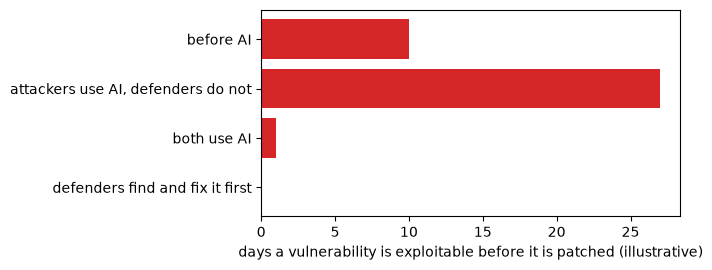

In [10]:
# Illustrative only. days_to_exploit: days from public disclosure until attackers have a working exploit.
# days_to_patch: days until the defender has applied the fix.
scenarios = [
    ("before AI",                          20, 30),
    ("attackers use AI, defenders do not",  3, 30),
    ("both use AI",                         3,  4),
    ("defenders find and fix it first",    3,  0),   # fixed before disclosure (e.g. found by own AI scanning)
]
rows = []
for name, t_exploit, t_patch in scenarios:
    exposure = max(0, t_patch - t_exploit)   # days attackers can use it before it is fixed
    rows.append((name, t_exploit, t_patch, exposure))
df_asym = pd.DataFrame(rows, columns=["scenario", "days to exploit", "days to patch", "exposed days"])
print(df_asym.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(df_asym["scenario"], df_asym["exposed days"], color="tab:red")
ax.set_xlabel("days a vulnerability is exploitable before it is patched (illustrative)")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 7. Threat modelling an AI app: STRIDE plus an AI extension

**What it is.** **Threat modelling** means thinking systematically, **before** an attacker does, about what could go wrong in a design. **STRIDE** (from Microsoft) is a checklist of six threat types. [Security for AI applications, section 1.2](../23_Software_Engineering/08_security_for_ai_applications.ipynb) introduces it; here we apply it to an AI app and **generate** the threat table in Python.

| Letter | Threat | Breaks | Simple example |
|---|---|---|---|
| S | **Spoofing** | authenticity | pretending to be another user |
| T | **Tampering** | integrity | changing data in transit or at rest |
| R | **Repudiation** | accountability | "I never did that" and there are no logs to prove it |
| I | **Information disclosure** | confidentiality | data leaks to the wrong person |
| D | **Denial of service** | availability | flooding the system so it stops working |
| E | **Elevation of privilege** | authorisation | a normal user gains admin powers |

**How it works.**
1. Draw a **data-flow diagram (DFD)**: external entities (people, outside systems), processes (code), data stores, and data flows between them. Mark **trust boundaries** (where data crosses from less trusted to more trusted).
2. For each element, list the STRIDE threats that apply to its type ("STRIDE-per-element").
3. Add **AI-specific threats**, because plain STRIDE misses some of them.
4. Write a mitigation for each threat, then score and rank them (section 8).

Our sample app: a **customer-support AI assistant** with RAG and two tools.

```mermaid
flowchart LR
    U[Customer<br/>external entity] -->|chat message| API[Chat API<br/>process]
    API -->|prompt| LLM[LLM<br/>process]
    LLM -->|query| VS[(Vector store<br/>help articles)]
    WEB[Uploaded docs and<br/>web pages<br/>external entity] -->|ingest| VS
    LLM -->|tool call| TOOLS[Tool executor<br/>process]
    TOOLS -->|read / refund| DB[(Orders DB<br/>data store)]
    API -->|write| LOG[(Audit log<br/>data store)]
    LLM -->|answer| API
    API -->|reply| U
```

The trust boundaries: between the customer and the API, between outside documents and the vector store, and between the LLM and the tools (the LLM's output must not be trusted blindly).

In [11]:
# 1) The data-flow elements of our toy app.
elements = [
    # name,               type
    ("Customer",            "external_entity"),
    ("Uploaded docs/web",   "untrusted_content"),  # outside content the AI will read
    ("Chat API",            "process"),
    ("LLM",                 "llm_process"),        # an AI-specific element type
    ("Tool executor",       "agent_tools"),        # an AI-specific element type
    ("Vector store",        "rag_store"),          # an AI-specific element type
    ("Orders DB",           "data_store"),
    ("Audit log",           "data_store"),
    ("Customer -> Chat API", "data_flow"),
    ("Docs -> Vector store", "data_flow"),
]

# 2) Classic STRIDE-per-element: which threat letters apply to each element type.
STRIDE_PER_TYPE = {
    "external_entity": "SR",
    "untrusted_content": "SR",
    "process":         "STRIDE",
    "data_store":      "TRID",
    "data_flow":       "TID",
    # the AI element types are also processes or stores in classic STRIDE terms:
    "llm_process":     "STRIDE",
    "agent_tools":     "STRIDE",
    "rag_store":       "TID",
}
STRIDE_NAMES = {"S": "Spoofing", "T": "Tampering", "R": "Repudiation",
                "I": "Information disclosure", "D": "Denial of service", "E": "Elevation of privilege"}

print(pd.DataFrame([(n, t, STRIDE_PER_TYPE[t]) for n, t in elements],
                   columns=["element", "type", "STRIDE letters"]).to_string(index=False))

             element              type STRIDE letters
            Customer   external_entity             SR
   Uploaded docs/web untrusted_content             SR
            Chat API           process         STRIDE
                 LLM       llm_process         STRIDE
       Tool executor       agent_tools         STRIDE
        Vector store         rag_store            TID
           Orders DB        data_store           TRID
           Audit log        data_store           TRID
Customer -> Chat API         data_flow            TID
Docs -> Vector store         data_flow            TID


**The AI extension.** Plain STRIDE does not name several threats that matter for AI apps. We add an **AI threat list** that maps onto the [OWASP Top 10 for LLM Applications 2025](https://genai.owasp.org/llm-top-10/) (LLM01-LLM10) and the OWASP agentic list (ASI01-ASI10). Each AI threat applies to certain element types.

In [12]:
# 3) AI-specific threats: (id, name, applies to element types, OWASP reference, mitigation)
AI_THREATS = [
    ("AI1", "Direct prompt injection / jailbreak",  {"llm_process"},               "LLM01",
     "system prompt is not a security boundary; input filters; output checks; refuse-by-policy"),
    ("AI2", "Indirect prompt injection via content", {"rag_store", "untrusted_content"}, "LLM01 / ASI01",
     "treat retrieved text as data; mark and quote it; strip instructions; restrict tools after reading untrusted text"),
    ("AI3", "Excessive agency / tool misuse",       {"agent_tools"},               "LLM06 / ASI02",
     "least-privilege tools; allowlist actions; human approval for refunds and writes; spending limits"),
    ("AI4", "Sensitive data in answers",            {"llm_process", "rag_store"},  "LLM02",
     "per-user access control on retrieval; PII redaction; never put secrets in prompts"),
    ("AI5", "System prompt leakage",                {"llm_process"},               "LLM07",
     "keep no secrets in the system prompt; enforce rules in code, not in the prompt"),
    ("AI6", "Data / knowledge-base poisoning",      {"rag_store"},                 "LLM04 / LLM08",
     "vet and sign sources; review uploads; track provenance; monitor for sudden content changes"),
    ("AI7", "Improper output handling",             {"agent_tools", "process"},    "LLM05",
     "validate model output against a schema; never eval/exec it; escape before rendering"),
    ("AI8", "Unbounded consumption (denial of wallet)", {"llm_process", "process"}, "LLM10",
     "rate limits per user; token and cost budgets; timeouts"),
    ("AI9", "Supply chain (models, packages, plugins)", {"llm_process", "agent_tools"}, "LLM03 / ASI04",
     "pin and hash dependencies; trusted model sources; scan plugins; SBOM"),
    ("AI10", "Misinformation / hallucinated answers", {"llm_process"},             "LLM09",
     "ground answers in sources; show citations; human escalation for policy questions"),
]

# Generic mitigations for the classic STRIDE letters.
STRIDE_MITIGATION = {
    "S": "strong authentication (MFA), signed service identities",
    "T": "integrity checks, TLS, write permissions only where needed",
    "R": "tamper-evident audit logs with user and agent IDs",
    "I": "encryption, access control, data minimisation",
    "D": "rate limits, quotas, autoscaling, timeouts",
    "E": "least privilege, authorisation checks on every call",
}

# 4) Generate the full threat table.
rows = []
for name, etype in elements:
    for letter in STRIDE_PER_TYPE[etype]:
        rows.append((name, etype, "STRIDE-" + letter, STRIDE_NAMES[letter], "-", STRIDE_MITIGATION[letter]))
    for tid, tname, types, ref, mitig in AI_THREATS:
        if etype in types:
            rows.append((name, etype, tid, tname, ref, mitig))

threats = pd.DataFrame(rows, columns=["element", "type", "threat_id", "threat", "owasp", "mitigation"])
print("total threats generated:", len(threats))
print("of which AI-specific:", threats["threat_id"].str.startswith("AI").sum())
print()
print(threats[threats["threat_id"].str.startswith("AI")][["element", "threat_id", "threat", "owasp"]].to_string(index=False))

total threats generated: 54
of which AI-specific: 15

          element threat_id                                   threat         owasp
Uploaded docs/web       AI2    Indirect prompt injection via content LLM01 / ASI01
         Chat API       AI7                 Improper output handling         LLM05
         Chat API       AI8 Unbounded consumption (denial of wallet)         LLM10
              LLM       AI1      Direct prompt injection / jailbreak         LLM01
              LLM       AI4                Sensitive data in answers         LLM02
              LLM       AI5                    System prompt leakage         LLM07
              LLM       AI8 Unbounded consumption (denial of wallet)         LLM10
              LLM       AI9 Supply chain (models, packages, plugins) LLM03 / ASI04
              LLM      AI10    Misinformation / hallucinated answers         LLM09
    Tool executor       AI3           Excessive agency / tool misuse LLM06 / ASI02
    Tool executor       AI7      

**What just happened?** From 10 diagram elements, the generator listed every classic STRIDE threat for each element type, then added the AI threats that apply. Many of the AI threats sit on the **LLM**, the **tool executor** and the **vector store**: those are the new parts of the attack surface. A generated list is a **starting point**: a human still removes threats that do not apply and adds ones the checklist missed.

Let us look at the full list for just one element, the tool executor, because tools are where an AI app can **act** in the world.

In [13]:
print(threats[threats["element"] == "Tool executor"][["threat_id", "threat", "mitigation"]].to_string(index=False))

threat_id                                   threat                                                                                       mitigation
 STRIDE-S                                 Spoofing                                           strong authentication (MFA), signed service identities
 STRIDE-T                                Tampering                                       integrity checks, TLS, write permissions only where needed
 STRIDE-R                              Repudiation                                                tamper-evident audit logs with user and agent IDs
 STRIDE-I                   Information disclosure                                                    encryption, access control, data minimisation
 STRIDE-D                        Denial of service                                                       rate limits, quotas, autoscaling, timeouts
 STRIDE-E                   Elevation of privilege                                              least privilege,

## 8. Risk scoring: likelihood x impact

**What it is.** You cannot fix everything at once, so you **rank** threats. The simplest method gives each threat a **likelihood** score (how likely is it to happen?) and an **impact** score (how bad would it be?), each from 1 to 5, and multiplies them. A score of 1-25 follows.

**Simple analogy.** A doctor's triage: a common, mild cold scores low; a rare but deadly condition and a common, serious one both score high.

**How it works.**
1. Score likelihood and impact (1 = very low, 5 = very high). Use the same written scale for everyone, so scores are comparable.
2. Risk = likelihood x impact. Map to bands: 1-4 low, 5-9 medium, 10-15 high, 16-25 critical.
3. Plan mitigations for the highest first. After mitigation, re-score: this is the **residual risk**.

**When not to use it.** The numbers are **judgements**, not measurements, and multiplying them can hide differences (a 1 x 5 and a 5 x 1 both give 5). For big decisions, teams use richer methods (for example FAIR, which estimates money losses). For a first ranking, likelihood x impact is fine.

The scores below are **illustrative** judgements for our toy app.

In [14]:
# Illustrative scores for a selection of threats: (threat_id, element, likelihood, impact,
# likelihood after mitigation, impact after mitigation)
scores = [
    ("AI2",      "Vector store",  4, 4, 2, 3),
    ("AI3",      "Tool executor", 3, 5, 1, 4),
    ("AI1",      "LLM",           5, 2, 4, 2),
    ("AI4",      "Vector store",  3, 4, 1, 4),
    ("AI8",      "LLM",           3, 3, 1, 2),
    ("AI6",      "Vector store",  2, 4, 1, 3),
    ("AI10",     "LLM",           4, 2, 3, 2),
    ("STRIDE-S", "Customer",      3, 3, 1, 3),
    ("STRIDE-R", "Audit log",     2, 3, 1, 2),
    ("STRIDE-E", "Tool executor", 2, 5, 1, 5),
]
risk = pd.DataFrame(scores, columns=["threat_id", "element", "L", "I", "L_after", "I_after"])
risk = risk.merge(threats[["element", "threat_id", "threat"]].drop_duplicates(), on=["element", "threat_id"], how="left")

def band(score):
    return "critical" if score >= 16 else "high" if score >= 10 else "medium" if score >= 5 else "low"

risk["risk"] = risk["L"] * risk["I"]
risk["band"] = risk["risk"].map(band)
risk["residual"] = risk["L_after"] * risk["I_after"]
risk["residual_band"] = risk["residual"].map(band)
risk = risk.sort_values("risk", ascending=False)
print(risk[["threat_id", "element", "threat", "L", "I", "risk", "band", "residual", "residual_band"]].to_string(index=False))

threat_id       element                                   threat  L  I  risk     band  residual residual_band
      AI2  Vector store    Indirect prompt injection via content  4  4    16 critical         6        medium
      AI3 Tool executor           Excessive agency / tool misuse  3  5    15     high         4           low
      AI4  Vector store                Sensitive data in answers  3  4    12     high         4           low
      AI1           LLM      Direct prompt injection / jailbreak  5  2    10     high         8        medium
 STRIDE-E Tool executor                   Elevation of privilege  2  5    10     high         5        medium
      AI8           LLM Unbounded consumption (denial of wallet)  3  3     9   medium         2           low
 STRIDE-S      Customer                                 Spoofing  3  3     9   medium         3           low
      AI6  Vector store          Data / knowledge-base poisoning  2  4     8   medium         3           low
     AI10 

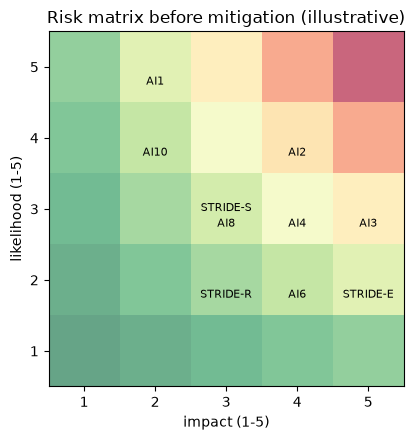

In [15]:
# A 5 x 5 risk matrix (heat map) with each threat placed in its cell.
grid = np.array([[l * i for i in range(1, 6)] for l in range(1, 6)])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(grid, origin="lower", cmap="RdYlGn_r", extent=(0.5, 5.5, 0.5, 5.5), alpha=0.6)
jitter = {}
for _, r in risk.iterrows():
    k = (r["I"], r["L"]); jitter[k] = jitter.get(k, 0) + 1
    ax.text(r["I"], r["L"] - 0.25 + 0.22 * (jitter[k] - 1), r["threat_id"], ha="center", fontsize=8)
ax.set_xlabel("impact (1-5)"); ax.set_ylabel("likelihood (1-5)")
ax.set_xticks(range(1, 6)); ax.set_yticks(range(1, 6))
ax.set_title("Risk matrix before mitigation (illustrative)")
plt.tight_layout(); plt.show()

**What just happened?** The top of the list (indirect prompt injection through the knowledge base, and tool misuse) is exactly where the AI app touches **untrusted content** and **real actions**. After mitigation, the residual risk drops, but **not to zero**: for example, direct prompt injection stays fairly likely because no filter is perfect, which is why the impact side (least privilege, human approval) matters so much. Notice also that "elevation of privilege on the tool executor" keeps impact 5 even after mitigation: if it ever happens, it is still very bad, so it deserves monitoring.

## 9. Timeline of notable, verified AI-security events (2024-2026)

Only events described in a **primary source** (the organisation's own report, an official advisory, a CVE, or a peer-reviewed paper) are listed. "Status" says how far the key claim can be checked from outside. This field moves fast; treat this as a snapshot as of late 2026.

In [16]:
events = [
    ("2024-02", "Deepfake video-call fraud at Arup (Hong Kong), about US$25M lost",          "Hong Kong police; Arup statement",             "verified"),
    ("2024-02", "OpenAI and Microsoft disrupt 5 state-affiliated actors; 'limited, incremental' uplift", "OpenAI / Microsoft reports",   "verified"),
    ("2024-11", "AI-written fuzz targets find 26 bugs incl. OpenSSL CVE-2024-9143",          "Google Security Blog",                         "verified"),
    ("2024-11", "FinCEN alert on deepfake media in fraud against banks",                     "FinCEN FIN-2024-Alert004",                     "verified"),
    ("2024-11", "Study: AI spear phishing 54% click rate vs 12% control",                    "Heiding et al., arXiv:2412.00586",             "verified (peer-reviewed later)"),
    ("2025-01", "GTIG 'Adversarial Misuse of Generative AI': mostly productivity gains",     "Google Threat Intelligence Group",             "verified"),
    ("2025-03", "NIST AI 100-2 E2025 adversarial ML taxonomy published",                     "NIST",                                         "verified"),
    ("2025-05", "FBI warns of AI voice messages impersonating senior US officials",          "FBI IC3 PSA I-051525-PSA",                     "verified"),
    ("2025-05", "NCSC: AI to increase intrusions to 2027; end-to-end autonomy unlikely",    "UK NCSC assessment",                           "verified (assessment)"),
    ("2025-06", "EchoLeak CVE-2025-32711: zero-click prompt injection in M365 Copilot",     "CVE; Aim Security; Microsoft",                 "verified, patched"),
    ("2025-06", "XBOW AI pentester tops HackerOne US leaderboard",                            "XBOW; HackerOne leaderboard",                  "verified ranking; human-reviewed"),
    ("2025-07", "Big Sleep finds SQLite CVE-2025-6965 before exploitation",                  "Google",                                       "CVE verified; 'foiled' is a claim"),
    ("2025-08", "DARPA AIxCC final: 54/63 planted bugs found, 18 real bugs, systems open-sourced", "DARPA",                                  "verified"),
    ("2025-08", "Anthropic: 'vibe hacking' extortion against 17+ organisations",             "Anthropic threat report",                      "verified (single source)"),
    ("2025-08", "Nx 's1ngularity' npm attack abuses installed AI CLIs to find secrets",       "Wiz; Socket",                                  "verified"),
    ("2025-09", "Shai-Hulud self-replicating npm worm",                                      "CISA alert",                                   "verified"),
    ("2025-11", "First malware using an LLM at runtime seen in live operations (PROMPTSTEAL)", "Google GTIG AI Threat Tracker",              "verified"),
    ("2025-11", "AI-orchestrated espionage campaign using Claude Code (about 30 targets)",   "Anthropic",                                    "verified (single source)"),
    ("2025-12", "OWASP Top 10 for Agentic Applications 2026 published",                     "OWASP GenAI Security Project",                 "verified"),
    ("2025-12", "NIST Cyber AI Profile (IR 8596) preliminary draft",                         "NIST",                                         "verified (draft)"),
    ("2026-01", "curl ends bug bounty, citing AI-generated low-quality reports",             "curl maintainer announcement",                 "verified"),
    ("2026-02", "CrowdStrike: 29-min average breakout; prompt injection at 90+ orgs",       "CrowdStrike 2026 Global Threat Report",        "vendor telemetry"),
    ("2026-04", "Project Glasswing: gated model for defensive vulnerability finding",        "Anthropic",                                    "examples verified; totals claimed"),
    ("2026-05", "First zero-day exploit GTIG believes was AI-developed; LiteLLM supply-chain compromise", "Google GTIG AI Threat Tracker", "verified report; AI role assessed"),
]
df_events = pd.DataFrame(events, columns=["when", "event", "source", "status"])
print(df_events.to_string(index=False))

   when                                                                                  event                                source                            status
2024-02                       Deepfake video-call fraud at Arup (Hong Kong), about US$25M lost      Hong Kong police; Arup statement                          verified
2024-02  OpenAI and Microsoft disrupt 5 state-affiliated actors; 'limited, incremental' uplift            OpenAI / Microsoft reports                          verified
2024-11                       AI-written fuzz targets find 26 bugs incl. OpenSSL CVE-2024-9143                  Google Security Blog                          verified
2024-11                                  FinCEN alert on deepfake media in fraud against banks              FinCEN FIN-2024-Alert004                          verified
2024-11                                 Study: AI spear phishing 54% click rate vs 12% control      Heiding et al., arXiv:2412.00586    verified (peer-reviewed later

**How to read this.** Notice the pattern: in 2024 most items are about **AI helping humans** (phishing text, deepfakes, fuzzing). In 2025-2026 the items move to **agents** (AI running many steps) and to **attacks on AI tools themselves** (prompt injection, AI CLIs, agent skills, AI gateways). Also notice how many entries are "single source" or "claimed": in this field, read the original report and its caveats before repeating a headline number.

## 10. The policy and regulation landscape (general terms)

Laws and guidance change quickly and differ by country. This is a map, not legal advice; check the official texts for anything you must comply with.

| Type | Examples (as of late 2026) | What it asks for, in simple words |
|---|---|---|
| **Voluntary frameworks** | NIST Cybersecurity Framework 2.0 (Govern, Identify, Protect, Detect, Respond, Recover); NIST AI Risk Management Framework (Govern, Map, Measure, Manage) and its Generative AI Profile (NIST AI 600-1); NIST Cyber AI Profile draft (secure AI, use AI to defend, thwart AI-enabled attacks) | a shared structure for managing cyber and AI risk |
| **Threat knowledge bases** | MITRE ATT&CK, MITRE ATLAS, NIST AI 100-2 (adversarial ML taxonomy), OWASP LLM and agentic Top 10 lists | a shared language for attacks and controls |
| **Certifiable standards** | ISO/IEC 27001 (information security), ISO/IEC 42001 (AI management systems) | an audited management system |
| **Government guidance** | UK/US "Guidelines for Secure AI System Development" (2023); CISA "Secure by Design"; CISA/NSA/FBI "AI Data Security" (May 2025); NCSC assessments | build security in from the start; protect training data |
| **Laws on AI** | EU AI Act: rules for general-purpose AI models apply since August 2025; obligations for high-risk systems were postponed in 2026 (check the current dates); national AI laws elsewhere | risk management, robustness and cybersecurity duties for some AI systems |
| **Laws on cyber and products** | EU NIS2 (cyber duties for important sectors); EU Cyber Resilience Act (security of products with digital elements, with reporting duties starting from 2026); breach-notification and data-protection laws (e.g. GDPR) | secure products, incident reporting, protect personal data |
| **Laws on computer misuse** | UK Computer Misuse Act, US CFAA, and equivalents | unauthorised access is a crime: only test with permission |
| **AI-lab policies** | usage policies, threat reports, "trusted access" programmes for verified defenders (OpenAI, Anthropic, Google) | labs restrict the most dangerous cyber capabilities and give vetted defenders more access |

## 11. Recap: cheat sheet

| Idea | One-line summary |
|---|---|
| CIA triad | protect confidentiality, integrity, availability |
| Threat / vulnerability / exploit | who could harm / the weakness / the method that uses it |
| Risk | likelihood x impact; rank and fix the biggest first |
| Attack surface | all the ways in; AI adds prompts, documents, tools, plugins, memory |
| Kill chain / ATT&CK | attacks are sequences of steps; break any step; map detections to tactics |
| Defence in depth | several **independent** layers; correlated layers protect less |
| Zero trust | verify every request; least privilege; treat AI agents as identities |
| AI and offence | mostly faster old playbooks; real firsts in agentic attacks, LLM-calling malware, an AI-developed zero-day |
| AI and phishing / deepfakes | fluency is no longer a warning sign; use phishing-resistant MFA and process controls |
| AI malware | behaviour stays the same when code changes, so detect behaviour |
| Attacks on AI | prompt injection, agent hijacking, poisoned tools; treat model inputs as untrusted |
| Supply chain | hallucinated and poisoned packages; allowlist, pin, scan |
| Asymmetry | the side that adopts AI faster gains; risk of a "digital divide" |
| Threat modelling | DFD -> STRIDE per element -> AI extension -> mitigations -> scores |
| Evidence | separate verified facts from vendor claims and single-source reports |

## 12. Interview questions

1. **What is the CIA triad?** Confidentiality, integrity and availability: the three properties security protects.
2. **Threat vs vulnerability vs risk?** A threat is who or what could cause harm, a vulnerability is a weakness, and risk combines the likelihood and the impact of harm.
3. **What is MITRE ATT&CK, and how is ATLAS different?** ATT&CK is a public knowledge base of real attacker tactics and techniques against IT systems. ATLAS is the equivalent for attacks on AI and ML systems.
4. **Why does defence in depth need independent layers?** If one trick beats several layers at once, the layers fail together, and the combined protection is much weaker than the product of their miss rates suggests.
5. **What does zero trust mean for an AI agent?** Give it its own identity, least-privilege tools, short-lived credentials, policy checks on each action, and full logging.
6. **Has AI created brand-new attack types?** Mostly it speeds up existing ones (NCSC, OpenAI, Google agree). The genuinely new parts are attacks on AI systems themselves (prompt injection, agent hijacking) and early agentic and LLM-calling malware.
7. **Why are AI-written phishing emails dangerous, and what is the best control?** They are fluent and personalised, so old warning signs disappear (a 2024 study measured 54% vs 12% clicks). Phishing-resistant MFA makes a stolen password insufficient.
8. **Why does behaviour-based detection still work against "polymorphic AI malware"?** Rewriting the code changes its hash, but not what it does on the machine; behaviour rules and network signals (such as calls to AI APIs) still match.
9. **What is slopsquatting?** Registering package names that AI coding assistants hallucinate, so that developers who trust the suggestion install malware.
10. **How would you threat-model an LLM agent?** Draw the data flows and trust boundaries, apply STRIDE per element, add AI threats (prompt injection, excessive agency, data leakage, poisoning, unbounded consumption, supply chain), choose mitigations, and rank by likelihood x impact.

## 13. Further reading

**Threat reports (primary sources)**
- Google Threat Intelligence Group, "Adversarial Misuse of Generative AI" (January 2025) and the "AI Threat Tracker" reports (November 2025; February and May 2026), cloud.google.com/blog/topics/threat-intelligence.
- Anthropic, "Detecting and countering misuse of AI: August 2025" and "Disrupting the first reported AI-orchestrated cyber espionage campaign" (November 2025), anthropic.com.
- OpenAI, "Disrupting malicious uses of AI" report series (2024-2026), openai.com/global-affairs.
- Microsoft Digital Defense Report 2025; CrowdStrike 2026 Global Threat Report.
- UK NCSC, "Impact of AI on cyber threat from now to 2027" (2025), ncsc.gov.uk.
- FBI IC3 PSA I-051525-PSA (May 2025); FinCEN Alert FIN-2024-Alert004 (November 2024).

**Research and competitions**
- F. Heiding et al., "Evaluating Large Language Models' Capability to Launch Fully Automated Spear Phishing Campaigns", arXiv:2412.00586.
- J. Spracklen et al., "We Have a Package for You! A Comprehensive Analysis of Package Hallucinations by Code Generating LLMs", USENIX Security 2025.
- A. Zhang et al., "Cybench: A Framework for Evaluating Cybersecurity Capabilities and Risks of Language Models", arXiv:2408.08926.
- DARPA, "AI Cyber Challenge marks pivotal inflection point for cyber defense" (AIxCC final results, August 2025).
- Google Security Blog, "Leveling up fuzzing: Finding more vulnerabilities with AI" (November 2024).

**Frameworks**
- MITRE ATT&CK (attack.mitre.org) and MITRE ATLAS (atlas.mitre.org).
- OWASP Top 10 for LLM Applications 2025 and OWASP Top 10 for Agentic Applications 2026 (genai.owasp.org).
- NIST AI 100-2 E2025, NIST CSF 2.0, NIST AI RMF 1.0 and AI 600-1, NIST IR 8596 (Cyber AI Profile, draft), NIST SP 800-207 (Zero Trust Architecture).
- A. Shostack, *Threat Modeling: Designing for Security*, Wiley, 2014.
- Lockheed Martin, "Intelligence-Driven Computer Network Defense Informed by Analysis of Adversary Campaigns and Intrusion Kill Chains" (Hutchins, Cloppert, Amin, 2011).

**In this repo**
- [Security for AI applications](../23_Software_Engineering/08_security_for_ai_applications.ipynb), [LLM security](../08_LLM/16_llm_security.ipynb), [agent security](../10_Agents/08_agent_security.ipynb), [adversarial attacks](../19_AI_Ethics_and_Safety/02_adversarial_attacks.ipynb), [deepfake detection](../19_AI_Ethics_and_Safety/07_deepfake_detection.ipynb), [red-teaming and incident response](../19_AI_Ethics_and_Safety/09_industry_ai_incident_response_and_red_teaming.ipynb).
- **Next in this track:** [02 Securing vibe-coded applications](02_securing_vibe_coded_applications.ipynb), [03 AI for cyber defence](03_ai_for_cyber_defense.ipynb), [04 Attacking and defending AI systems](04_attacking_and_defending_ai_systems.ipynb).